In [1]:
import sys
if not '../..' in sys.path:
    sys.path.append('../..')
    sys.path.append('..')
from analysis import collection, analysis, emg, plot, model
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import patches, lines
from pathlib import Path
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from joblib import dump, load
from analysis.offsets import offsets
from numpy.random import default_rng

mpl.rcParams.update(mpl.rcParamsDefault)
mpl.rcParams.update({'axes.labelsize': 16})
mpl.rcParams.update({'figure.figsize': (16*0.8,9*0.8)})
mpl.rcParams.update({'axes.facecolor': "white"})
mpl.rcParams.update({'lines.marker': "+"})
mpl.rcParams.update({'lines.linestyle': ""})
mpl.rcParams.update({"axes.spines.left":   True})
mpl.rcParams.update({"axes.spines.bottom": True})
mpl.rcParams.update({"axes.spines.top":    False})
mpl.rcParams.update({"axes.spines.right":  False})

image_path = Path("/Users/spencer/phd/phd/images/more_results/gmms/")

%matplotlib inline

from scipy.stats import multivariate_normal

In [43]:
N = 2
m = np.zeros(shape=(N,))
c = np.eye(N)

var = multivariate_normal(mean=m, cov=c)

In [44]:
decoder = np.random.normal((2,N))

just brute force it:

- take a ton of samples from the original gaussian
- filter those which are outside the n_std range: 0.9mu*Sigma*0.9mu < (x-mu)Sigma(x-mu) < 1.1mu*Sigma*1.1mu

In [45]:
rng = default_rng(293829472)
# take samples
samples = var.rvs(size=5000,random_state=rng)
samples.shape

(5000, 2)

In [46]:
def mahalanobis(x,mu,sigma):
    return np.sqrt((x-mu.reshape(-1,1)).T @ np.linalg.inv(sigma) @ (x-mu.reshape(-1,1)))

In [47]:
sample_mahal = []
for xx in samples:
    sample_mahal += [mahalanobis(xx.reshape(-1,1),m,c)[0,0]]
sample_mahal = np.array(sample_mahal)
sample_mahal.shape

(5000,)

In [48]:
# whitening matrix

def whitening_matrix(c):
    # c = WW.T
    return np.linalg.cholesky(c).T

W = whitening_matrix(c)

In [49]:
# distance from mean in normal space
# z = sqrt((x-mu)**2/var)
# x = sqrt(var*z**2) + mu

# d_mahal_xy = np.linalg.norm(W @ (x-y))
# z**2 = sum (  )

def compute_z_score_bounds(m,c):
    # zdown = 0.499
    # zup = 0.501
    eps = 0.01
    # xup = (np.sqrt(zup**2*np.trace(c)) + m).reshape(-1,1)
    # xdown = (np.sqrt(zdown**2*np.trace(c)) + m).reshape(-1,1)
    # mahal_up = mahalanobis(np.sqrt(N)+eps,m,c)[0,0]
    # mahal_down = mahalanobis(np.sqrt(N)-eps,m,c)[0,0]
    return np.sqrt(N)+eps, np.sqrt(N)-eps

(1.4242135623730952, 1.4042135623730951)

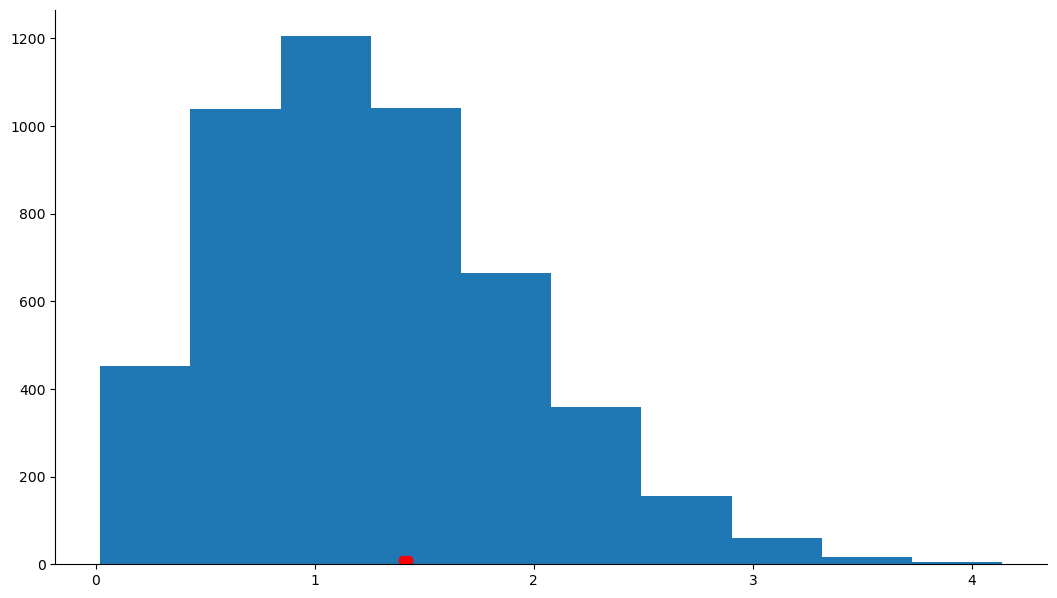

In [50]:
plt.hist(sample_mahal)
up, down = compute_z_score_bounds(m,c)
plt.plot(up,10,"ro")
plt.plot(down,10,"ro")
up, down

In [51]:
samples_in_range = samples[np.where((down < sample_mahal) * (sample_mahal < up))]

In [52]:
samples_in_range.shape

(49, 2)

In [53]:
# samples = (decoder @ samples.T).T
# samples_in_range = (decoder @ samples_in_range.T).T

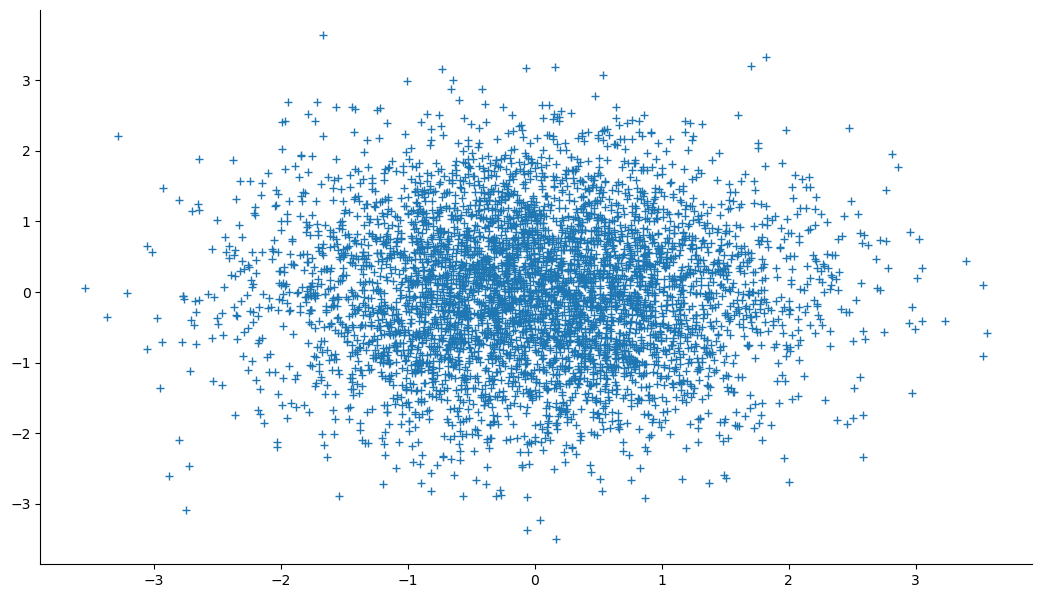

In [54]:
samples.shape
plt.plot(samples[:,0],samples[:,1])

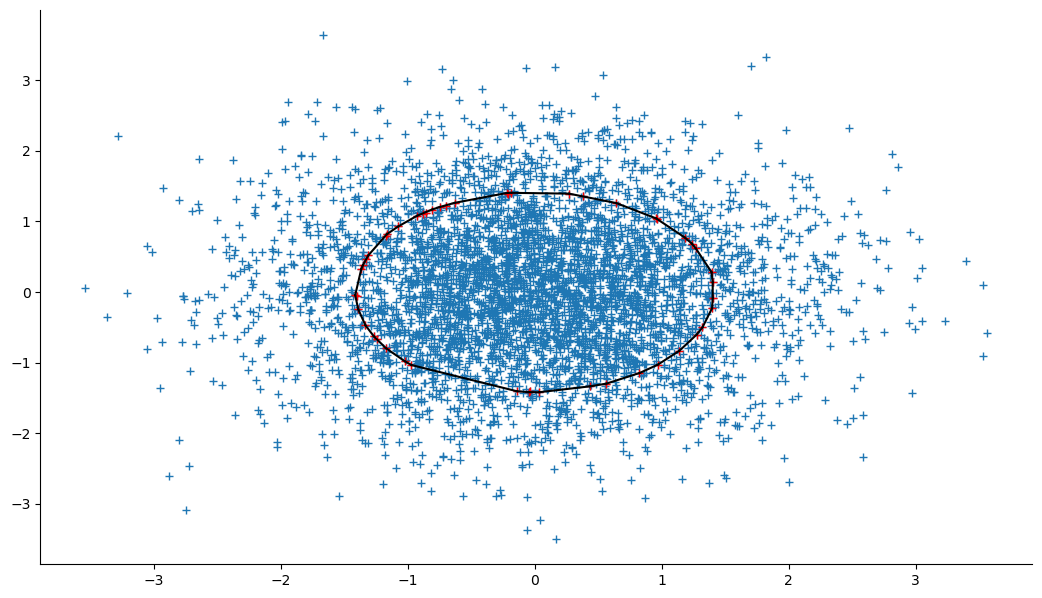

In [55]:
from scipy.spatial import ConvexHull, convex_hull_plot_2d

plt.plot(samples[:,0],samples[:,1])
plt.plot(samples_in_range[:,0],samples_in_range[:,1],"r")

hull = ConvexHull(samples_in_range)
for simplex in hull.simplices:
    plt.plot(samples_in_range[simplex, 0], samples_in_range[simplex, 1], 'k-')

In [5]:
plt.plot(np.exp(samples)[:,0],np.exp(samples)[:,1])
plt.plot(np.exp(samples_in_range)[:,0],np.exp(samples_in_range)[:,1],"r")

NameError: name 'samples' is not defined

Ok, this is basically a dead end.

Next steps:

- Just try plotting the fits better, and make sure we're transforming correctly from the original space

- Try generating a notion of residual by:
    - finding the nearest points of the two sets (og samples and fitted samples)
    - computing residuals (||pairwise distance||)
    - plotting residuals looking for gaussian error

In [ ]:
N = 2
m = np.zeros(shape=(N,))
c = np.eye(N)

var = multivariate_normal(mean=m, cov=c)

rng = default_rng(293829472)
# take samples
samples = var.rvs(size=5000,random_state=rng)
samples.shape

In [52]:
N = 2
k = 500
m = np.zeros(shape=(N,))
c = np.eye(N)

var = multivariate_normal(mean=m, cov=c)

rng = default_rng(293829472)
# take samples
samples1 = var.rvs(size=k,random_state=rng)
samples2 = var.rvs(size=k,random_state=rng)
samples1.shape, samples2.shape

((500, 2), (500, 2))

In [53]:
import scipy
D = scipy.spatial.distance_matrix(samples1, samples2)
assignment1, assignment2 = scipy.optimize.linear_sum_assignment(D)

In [54]:
assignment1.shape, assignment2.shape

((500,), (500,))

In [66]:
assignment1

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

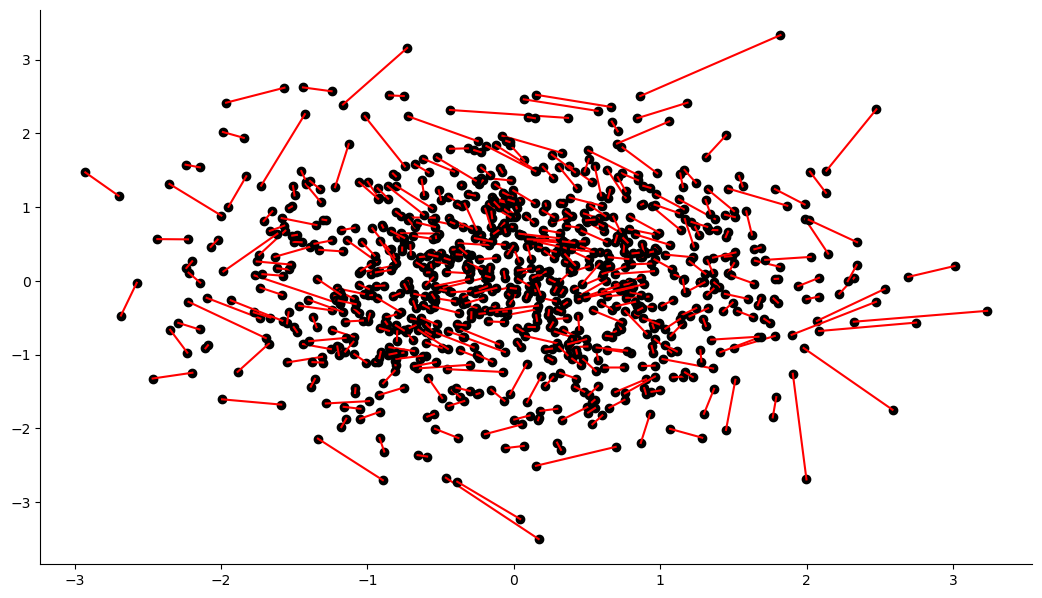

In [68]:
for i in range(500):
    plt.plot(samples1[assignment1[i]][0],samples1[assignment1[i]][1],"ko")
    plt.plot(samples2[assignment2[i]][0],samples2[assignment2[i]][1],"ko")
    plt.plot([samples1[assignment1[i]][0],samples2[assignment2[i]][0]],[samples1[assignment1[i]][1],samples2[assignment2[i]][1]],marker="",color="r",linestyle="-")

(array([273., 136.,  50.,  19.,  10.,   4.,   3.,   3.,   1.,   1.]),
 array([0.00150346, 0.14490226, 0.28830105, 0.43169984, 0.57509863,
        0.71849742, 0.86189621, 1.005295  , 1.14869379, 1.29209258,
        1.43549138]),
 <BarContainer object of 10 artists>)

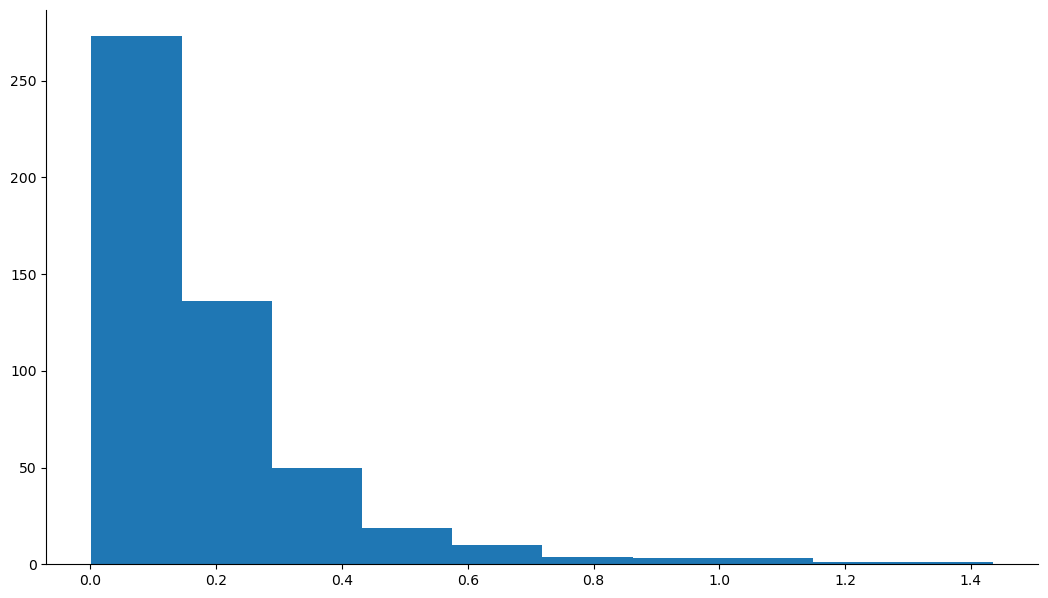

In [71]:
residuals = np.array([D[i][j] for i,j in zip(assignment1,assignment2)])
plt.hist(residuals)

I have N-dimensional multivariate Gaussian fit to lognormal data-- I've log'd the samples in the original space, thus they're normally distributed, then I've fit a Gaussian.

I want to pull that data back into lognormal space (exponentiating it), then "decode" it by projecting onto a 2D plane (I have a 2xN decoder matrix).

I want to plot for the decoded lognormal data, in 2D, the "z-score" ellipse (or an approximation).

To do this, I have to find samples for the z-score of the fitted Gaussian, then exponentiate those, then decode those.

I'm having trouble finding the z-score, which for the multivariate Gaussian are samples with a certain Mahalanobis distance: sqrt((x-mu).T @ Sigma_inv @ (x-mu))

To find my z-score ellipsoid, I'm sampling from the Gaussian, then for each sample I'm computing its the Mahalanobis distance. What I need is the target Mahalanobis distance to get 1 "standard deviation" from the mean, something like:

1 = sqrt((x-mu).T @ Sigma_inv @ (x-mu)) and we solve for x?

Ok, forget the residual idea-- we don't have a way (a statistic) to tell us how good the residuals are.

Let's try to plot the density after transforming, and compare samples to fits.

In [78]:
import scipy.stats as st

def kde_plot(samples, ax):
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    # xmin, xmax = np.min(samples[:,0]), np.max(samples[:,0])
    # ymin, ymax = np.min(samples[:,1]), np.max(samples[:,1])

    # Peform the kernel density estimate
    xx, yy = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]
    positions = np.vstack([xx.ravel(), yy.ravel()])

    kernel = st.gaussian_kde(samples.T)
    f = np.reshape(kernel(positions).T, xx.shape)

    # Contourf plot
    cfset = ax.contourf(xx, yy, f, cmap='Blues')

    ## Or kernel density estimate plot instead of the contourf plot
    #ax.imshow(np.rot90(f), cmap='Blues', extent=[xmin, xmax, ymin, ymax])

    # Contour plot
    cset = ax.contour(xx, yy, f, colors='k')

    # Label plot
    ax.clabel(cset, inline=1, fontsize=10)

In [3]:
subjects = analysis.load_subjects()

## natural movement and calibration

In [97]:
subject_idx = 29
# subject_idx = 33
# subject_idx = 0
# subject_idx = 21
# subject_idx = 6
# subject_idx = 16
# subject_idx = 9

decoder = subjects[subject_idx].decoder[-2:,:]

movement_stack = np.load("../subject_filtered_movement_stacks.npy")[subject_idx]
decoder = subjects[subject_idx].decoder[-2:,:]
movement_samples = decoder @ analysis.remove_nan_rows(movement_stack.transpose(0,1,3,2).reshape(-1,64)).T

movement_N = movement_samples.shape[1]
movement_model = model.load_log_movement_models(subject_idx)[0]
movement_model_samples = decoder @ np.exp(movement_model.sample(movement_N)[0]).T

calibration_stack = np.load("../subject_filtered_calibration_stacks.npy")[subject_idx]
decoder = subjects[subject_idx].decoder[-2:,:]
calibration_samples = decoder @ analysis.remove_nan_rows(calibration_stack.transpose(0,1,3,2).reshape(-1,64)).T

calibration_N = calibration_samples.shape[1]
calibration_model = model.load_log_calibration_models(subject_idx)[0]
calibration_model_samples = decoder @ np.exp(calibration_model.sample(calibration_N)[0]).T

print(calibration_samples.shape, calibration_model_samples.shape)
print(movement_samples.shape, movement_model_samples.shape)

(2, 116520) (2, 116520)
(2, 21311) (2, 21311)


Text(0.5, 102.72222222222219, 'Model')

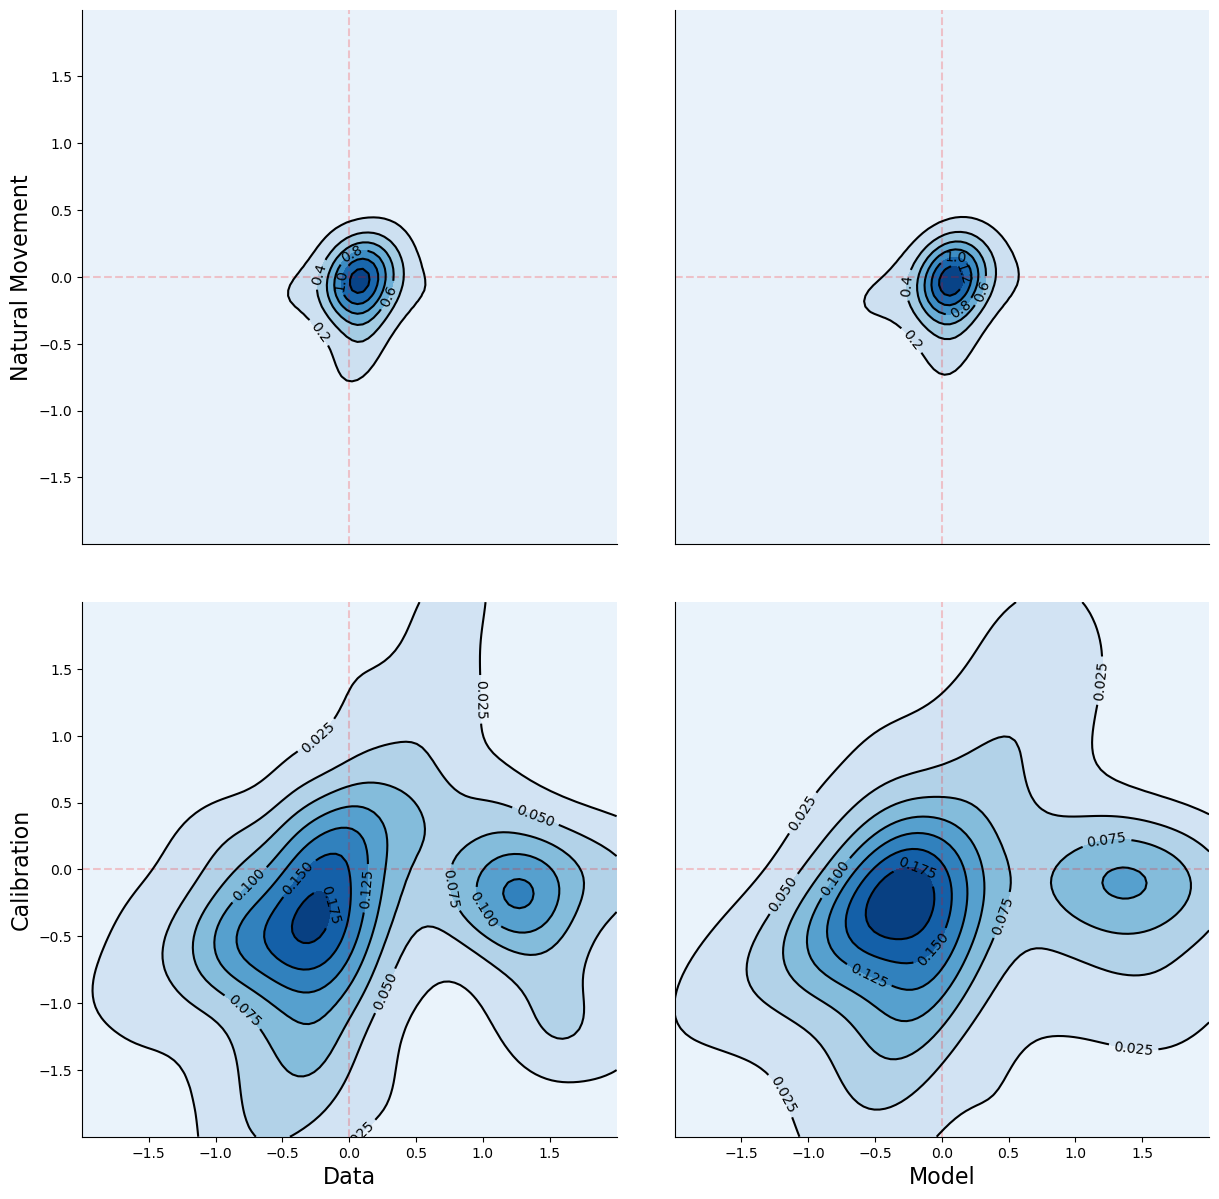

In [98]:
fig, model_axes = plt.subplots(2,2,figsize=(12,12))
fig.tight_layout()

for model_ax in model_axes.ravel():
    model_ax.set_aspect("equal")
    model_ax.set_ylim([-2,2])
    model_ax.set_xlim([-2,2])
    model_ax.plot([-2,2],[0,0],"r--",alpha=0.2)
    model_ax.plot([0,0],[-2,2],"r--",alpha=0.2)

# ms = movement_samples.T-offsets[subject_idx]
# model_axes[0,0].plot(ms[:,0],ms[:,1],".",alpha=0.1,color="tab:red")
kde_plot(movement_samples.T-offsets[subject_idx],model_axes[0,0])
kde_plot(movement_model_samples.T-offsets[subject_idx],model_axes[0,1])

kde_plot(calibration_samples.T-offsets[subject_idx],model_axes[1,0])
kde_plot(calibration_model_samples.T-offsets[subject_idx],model_axes[1,1])

for i in range(2):
    for j in range(2):
        ax = model_axes[i,j]
        ax.set_xticks(np.linspace(-1.5,1.5,7,endpoint=True))
        ax.set_yticks(np.linspace(-1.5,1.5,7,endpoint=True))

model_axes[0,0].set_ylabel("Natural Movement",fontsize=16)
model_axes[1,0].set_ylabel("Calibration",fontsize=16)

model_axes[0,0].set_xticks([])
model_axes[0,1].set_yticks([])
model_axes[0,1].set_xticks([])
model_axes[1,1].set_yticks([])

model_axes[1,0].set_xlabel("Data",fontsize=16)
model_axes[1,1].set_xlabel("Model",fontsize=16)


In [99]:
plot.save_figure(fig, f"subject_{subject_idx}_kde_movement_calibration", image_path)

Figure saved to /Users/spencer/phd/phd/images/more_results/gmms/subject_29_kde_movement_calibration.pdf


## Trial data

In [83]:
# subject_idx = 29
# subject_idx = 33
# subject_idx = 0
# subject_idx = 21
subject_idx = 6
subject_idx = 16
# subject_idx = 9

decoder = subjects[subject_idx].decoder[-2:,:]
models = model.load_log_trial_models(subject_idx)
stack = analysis.load_trial_stack(subject_idx=subject_idx)

model_decoded_samples = []
data_samples = []

for i in range(5):

    block_chunks = [(i,j) for i,j in zip(range(0,46,9),range(9,46,9))]
    m = models[i]

    chunk_samples = decoder @ analysis.remove_nan_rows(stack[block_chunks[i][0]:block_chunks[i][1]].transpose(0,1,3,2).reshape(-1,64)).T
    # data_samples += [chunk_samples[:,np.random.choice(np.arange(chunk_samples.shape[1]),N)]]
    data_samples += [chunk_samples]

    N = chunk_samples.shape[1]
    model_samples = m.sample(N)[0]
    model_exp_samples = np.exp(model_samples)
    model_decoded_samples += [decoder @ model_exp_samples.T]

    print(model_decoded_samples[-1].shape, chunk_samples.shape)


(2, 34458) (2, 34458)
(2, 19921) (2, 19921)
(2, 20603) (2, 20603)
(2, 16565) (2, 16565)
(2, 18672) (2, 18672)


Text(337.59722222222223, 0.5, 'Model')

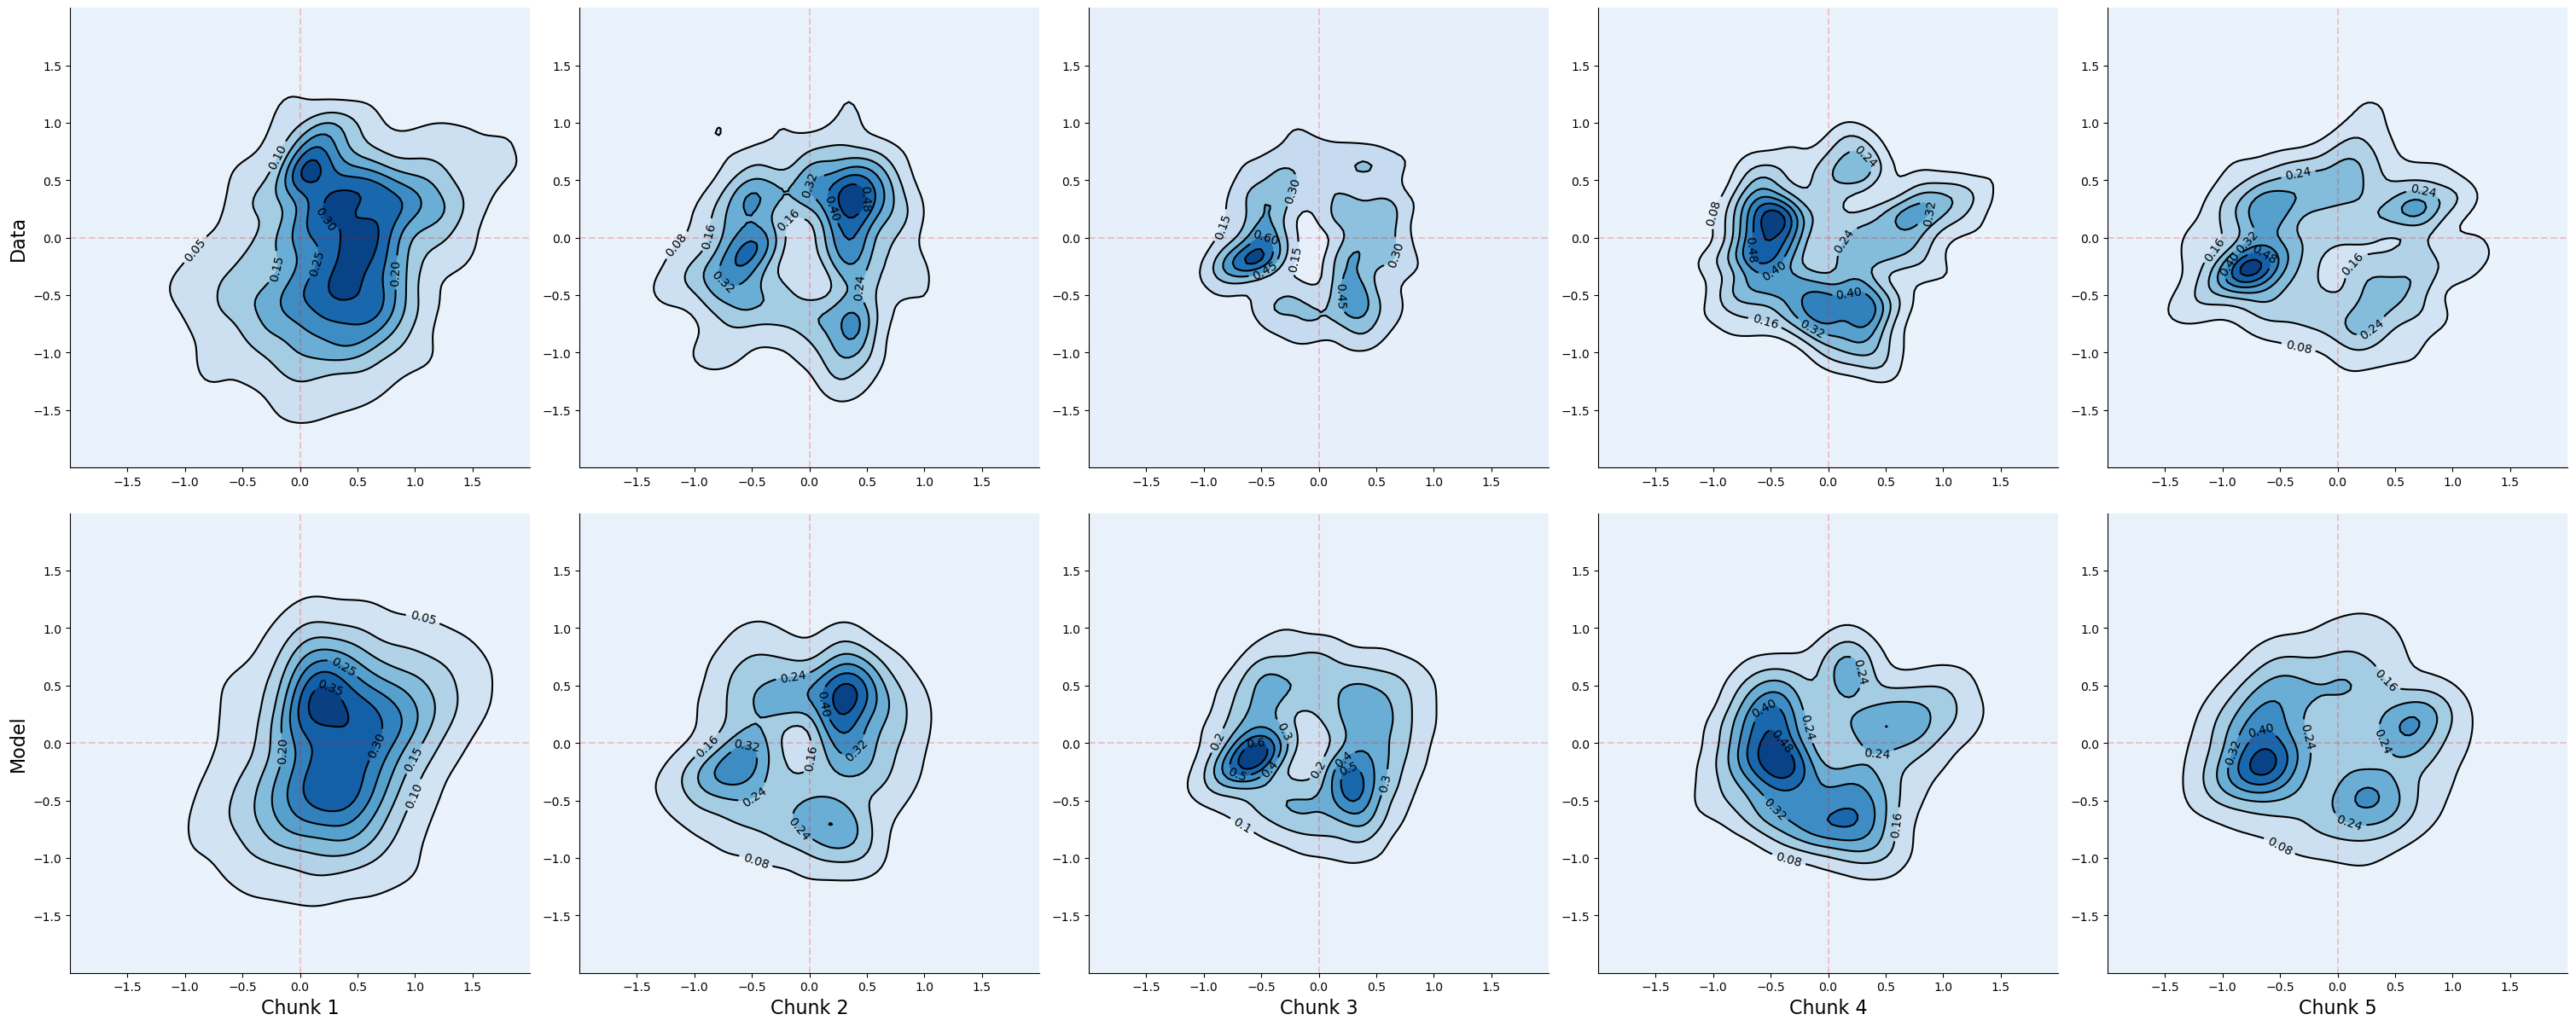

In [84]:
fig, model_axes = plt.subplots(2,5,figsize=(12*2.5,12))
fig.tight_layout()

for model_ax in model_axes.ravel():
    model_ax.set_aspect("equal")
    model_ax.set_ylim([-2,2])
    model_ax.set_xlim([-2,2])
    model_ax.plot([-2,2],[0,0],"r--",alpha=0.2)
    model_ax.plot([0,0],[-2,2],"r--",alpha=0.2)


for j in range(5):
    # m = models[i]
    # for (mm, cc, ww) in zip(m.means_, m.covariances_, m.weights_):
    #     mean = model.transform_mean(decoder, model.make_lognormal_mean(mm.reshape(-1,1),cc))
    #     model_axes[i,1].plot(mean[0],mean[1],"ro",markersize=500**ww)

    chunk_samples = data_samples[j]
    model_samples = model_decoded_samples[j]
    
    # model_axes[0].plot(chunk_samples[0],chunk_samples[1],'k.')
    kde_plot(chunk_samples.T-offsets[subject_idx],model_axes[0,j])

    # model_axes[1].plot(model_decoded_samples[0],model_decoded_samples[1],"k.")
    kde_plot(model_samples.T-offsets[subject_idx],model_axes[1,j])

for i in range(2):
    for j in range(5):
        ax = model_axes[i,j]
        ax.set_xticks(np.linspace(-1.5,1.5,7,endpoint=True))
        ax.set_yticks(np.linspace(-1.5,1.5,7,endpoint=True))
        if i == 1:
            ax.set_xlabel(f"Chunk {j+1}",fontsize=16)

model_axes[0,0].set_ylabel("Data",fontsize=16)
model_axes[1,0].set_ylabel("Model",fontsize=16)

In [85]:
plot.save_figure(fig, f"subject_{subject_idx}_kde_trial", image_path)

Figure saved to /Users/spencer/phd/phd/images/more_results/gmms/subject_16_kde_trial.pdf


## raw data 

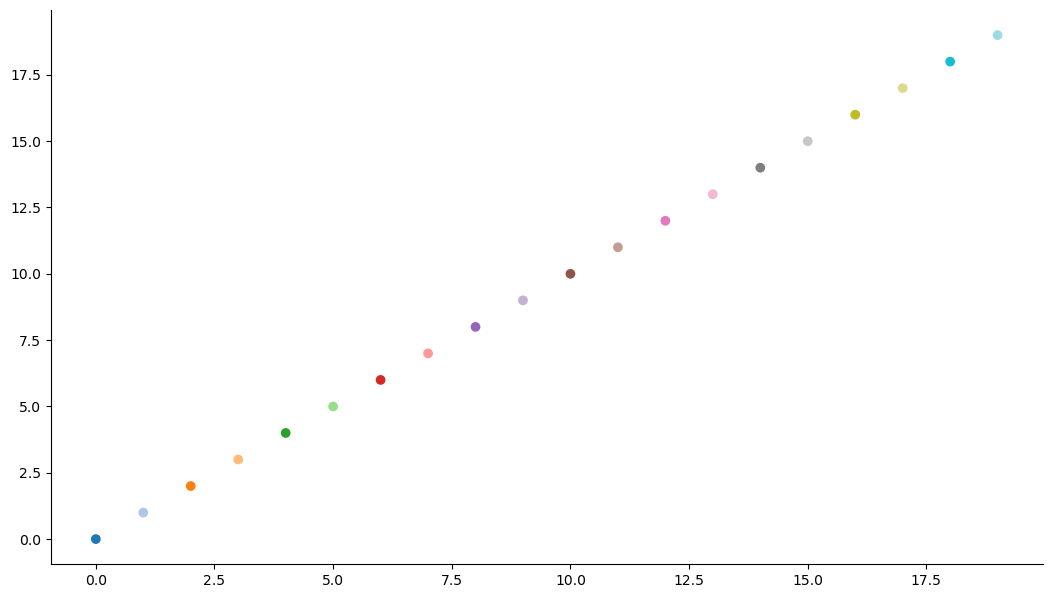

In [22]:
cmap = mpl.colormaps['tab20']
cmap(12)

plt.scatter(np.arange(20),np.arange(20),marker='o',color=cmap(np.linspace(0,1,20,endpoint=True)))

5600


/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn

12800


/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn

Text(0.5, 102.72222222222219, 'Model')

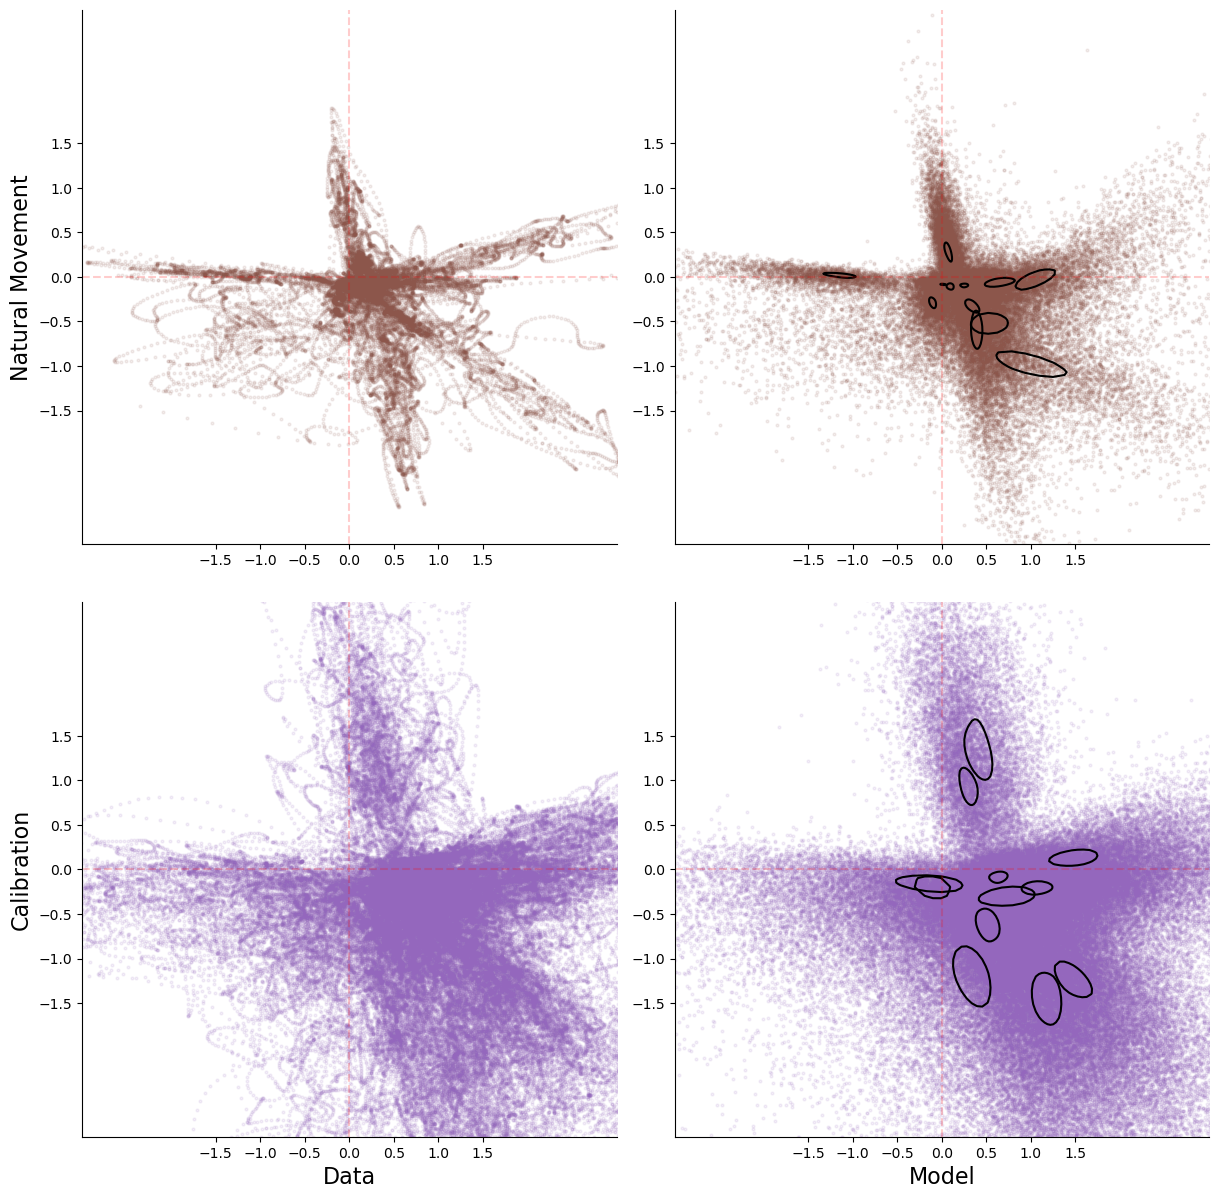

In [34]:
subject_idx = 9
cmap = mpl.colormaps['nipy_spectral']

def plot_movement_samples(subject_idx, data_ax, model_ax):
    stack = np.load("../subject_filtered_movement_stacks.npy")[subject_idx]
    decoder = subjects[subject_idx].decoder[-2:,:]
    samples = decoder @ stack.transpose(0,1,3,2).reshape(-1,64).T
    data_ax.plot(samples[0],samples[1],".",markersize=4,color='tab:brown',alpha=0.1,zorder=0)
    # data_ax.plot(samples[0],samples[1],".",markersize=4,color='tab:blue',alpha=0.1,zorder=0)

    subject_model = model.load_log_movement_models(subject_idx)[0]
    N = samples.shape[1]
    model_samples, model_components = subject_model.sample(N)
    model_exp_samples = np.exp(model_samples)
    decoded_samples = decoder @ model_exp_samples.T
    model_ax.plot(decoded_samples[0],decoded_samples[1],'.',color="tab:brown",markersize=4,alpha=0.1)
    # model_ax.scatter(decoded_samples[0],decoded_samples[1],marker='.',color=cmap(model_components/12),s=8,alpha=0.1)

    N = N // 10
    print(N)
    for i in range(12):
        g = GaussianMixture(n_components=1)
        g.means_ = subject_model.means_[i].reshape(1,64)
        g.covariances_ = subject_model.covariances_[i].reshape(1,64,64)
        g.weights_ = subject_model.weights_[i].reshape(1)
        lognormal_samples = np.exp(g.sample(N)[0])
        decoded_samples = decoder @ lognormal_samples.T
        data = pd.DataFrame(decoded_samples.T,columns=['x','y'])
        sns.kdeplot(data, x='x', y='y', levels=[0.95,1.0], ax=model_ax, color='k')
        # kde_plot(model_samples.T-offsets[subject_idx],model_axes[1,j])

def plot_calibration_samples(subject_idx, data_ax, model_ax):
    stack = np.load("../subject_filtered_calibration_stacks.npy")[subject_idx]
    decoder = subjects[subject_idx].decoder[-2:,:]
    samples = decoder @ stack.transpose(0,1,3,2).reshape(-1,64).T
    decoder = subjects[subject_idx].decoder[-2:,:]
    data_ax.plot(samples[0],samples[1],".",markersize=4,color='tab:purple',alpha=0.1,zorder=0)
    # data_ax.scatter(samples[0],samples[1],marker=".",s=8,color='tab:blue',alpha=0.1,zorder=0)

    subject_model = model.load_log_calibration_models(subject_idx)[0]
    N = samples.shape[1]
    model_samples, model_components = subject_model.sample(N)
    model_exp_samples = np.exp(model_samples)
    decoded_samples = decoder @ model_exp_samples.T
    model_ax.plot(decoded_samples[0],decoded_samples[1],'.',color="tab:purple",markersize=4,alpha=0.1)
    # model_ax.scatter(decoded_samples[0],decoded_samples[1],marker='.',color=cmap(model_components/12),s=8,alpha=0.1)

    N = N // 12
    print(N)
    for i in range(12):
        g = GaussianMixture(n_components=1)
        g.means_ = subject_model.means_[i].reshape(1,64)
        g.covariances_ = subject_model.covariances_[i].reshape(1,64,64)
        g.weights_ = subject_model.weights_[i].reshape(1)
        lognormal_samples = np.exp(g.sample(N)[0])
        decoded_samples = decoder @ lognormal_samples.T
        data = pd.DataFrame(decoded_samples.T,columns=['x','y'])
        sns.kdeplot(data, x='x', y='y', levels=[0.95,1.0], ax=model_ax, color='k')
        # kde_plot(model_samples.T-offsets[subject_idx],model_axes[1,j])

fig, axes = plt.subplots(2,2,figsize=(12,12))
fig.tight_layout()

plot_movement_samples(subject_idx,axes[0,0],axes[0,1])
plot_calibration_samples(subject_idx,axes[1,0],axes[1,1])

for ax in axes.ravel():
    ax.set_aspect("equal")
    ax.set_xticks(np.linspace(-1.5,1.5,7,endpoint=True))
    ax.set_yticks(np.linspace(-1.5,1.5,7,endpoint=True))
    ax.set_ylim([-3,3])
    ax.set_xlim([-3,3])
    ax.plot([-3,3],[0,0],"r--",alpha=0.2)
    ax.plot([0,0],[-3,3],"r--",alpha=0.2)
    ax.set(xlabel="")
    ax.set(ylabel="")

#        Data Model
# Mvmt   0,0  0,1
# Calib  1,0  1,1

axes[0,0].set_ylabel("Natural Movement",fontsize=16)
axes[1,0].set_ylabel("Calibration",fontsize=16)
axes[1,0].set_xlabel("Data",fontsize=16)
axes[1,1].set_xlabel("Model",fontsize=16)

In [35]:
plot.save_figure(fig, f"subject_{subject_idx}_data_model_prior", image_path, format='png')

Figure saved to /Users/spencer/phd/phd/images/more_results/gmms/subject_9_data_model_prior.png


## trial data points

In [36]:
# subject_idx = 29
# subject_idx = 33
# subject_idx = 0
# subject_idx = 21
subject_idx = 6
subject_idx = 16
# subject_idx = 9

decoder = subjects[subject_idx].decoder[-2:,:]
subject_models = model.load_log_trial_models(subject_idx)
stack = analysis.load_trial_stack(subject_idx=subject_idx)

model_decoded_samples = []
data_samples = []

for i in range(5):

    block_chunks = [(i,j) for i,j in zip(range(0,46,9),range(9,46,9))]
    m = subject_models[i]

    chunk_samples = decoder @ analysis.remove_nan_rows(stack[block_chunks[i][0]:block_chunks[i][1]].transpose(0,1,3,2).reshape(-1,64)).T
    # data_samples += [chunk_samples[:,np.random.choice(np.arange(chunk_samples.shape[1]),N)]]
    data_samples += [chunk_samples]

    N = chunk_samples.shape[1]
    model_samples = m.sample(N)[0]
    model_exp_samples = np.exp(model_samples)
    model_decoded_samples += [decoder @ model_exp_samples.T]

    print(model_decoded_samples[-1].shape, chunk_samples.shape)


(2, 34458) (2, 34458)
(2, 19921) (2, 19921)
(2, 20603) (2, 20603)
(2, 16565) (2, 16565)
(2, 18672) (2, 18672)


/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/seaborn

Text(337.59722222222223, 0.5, 'Model')

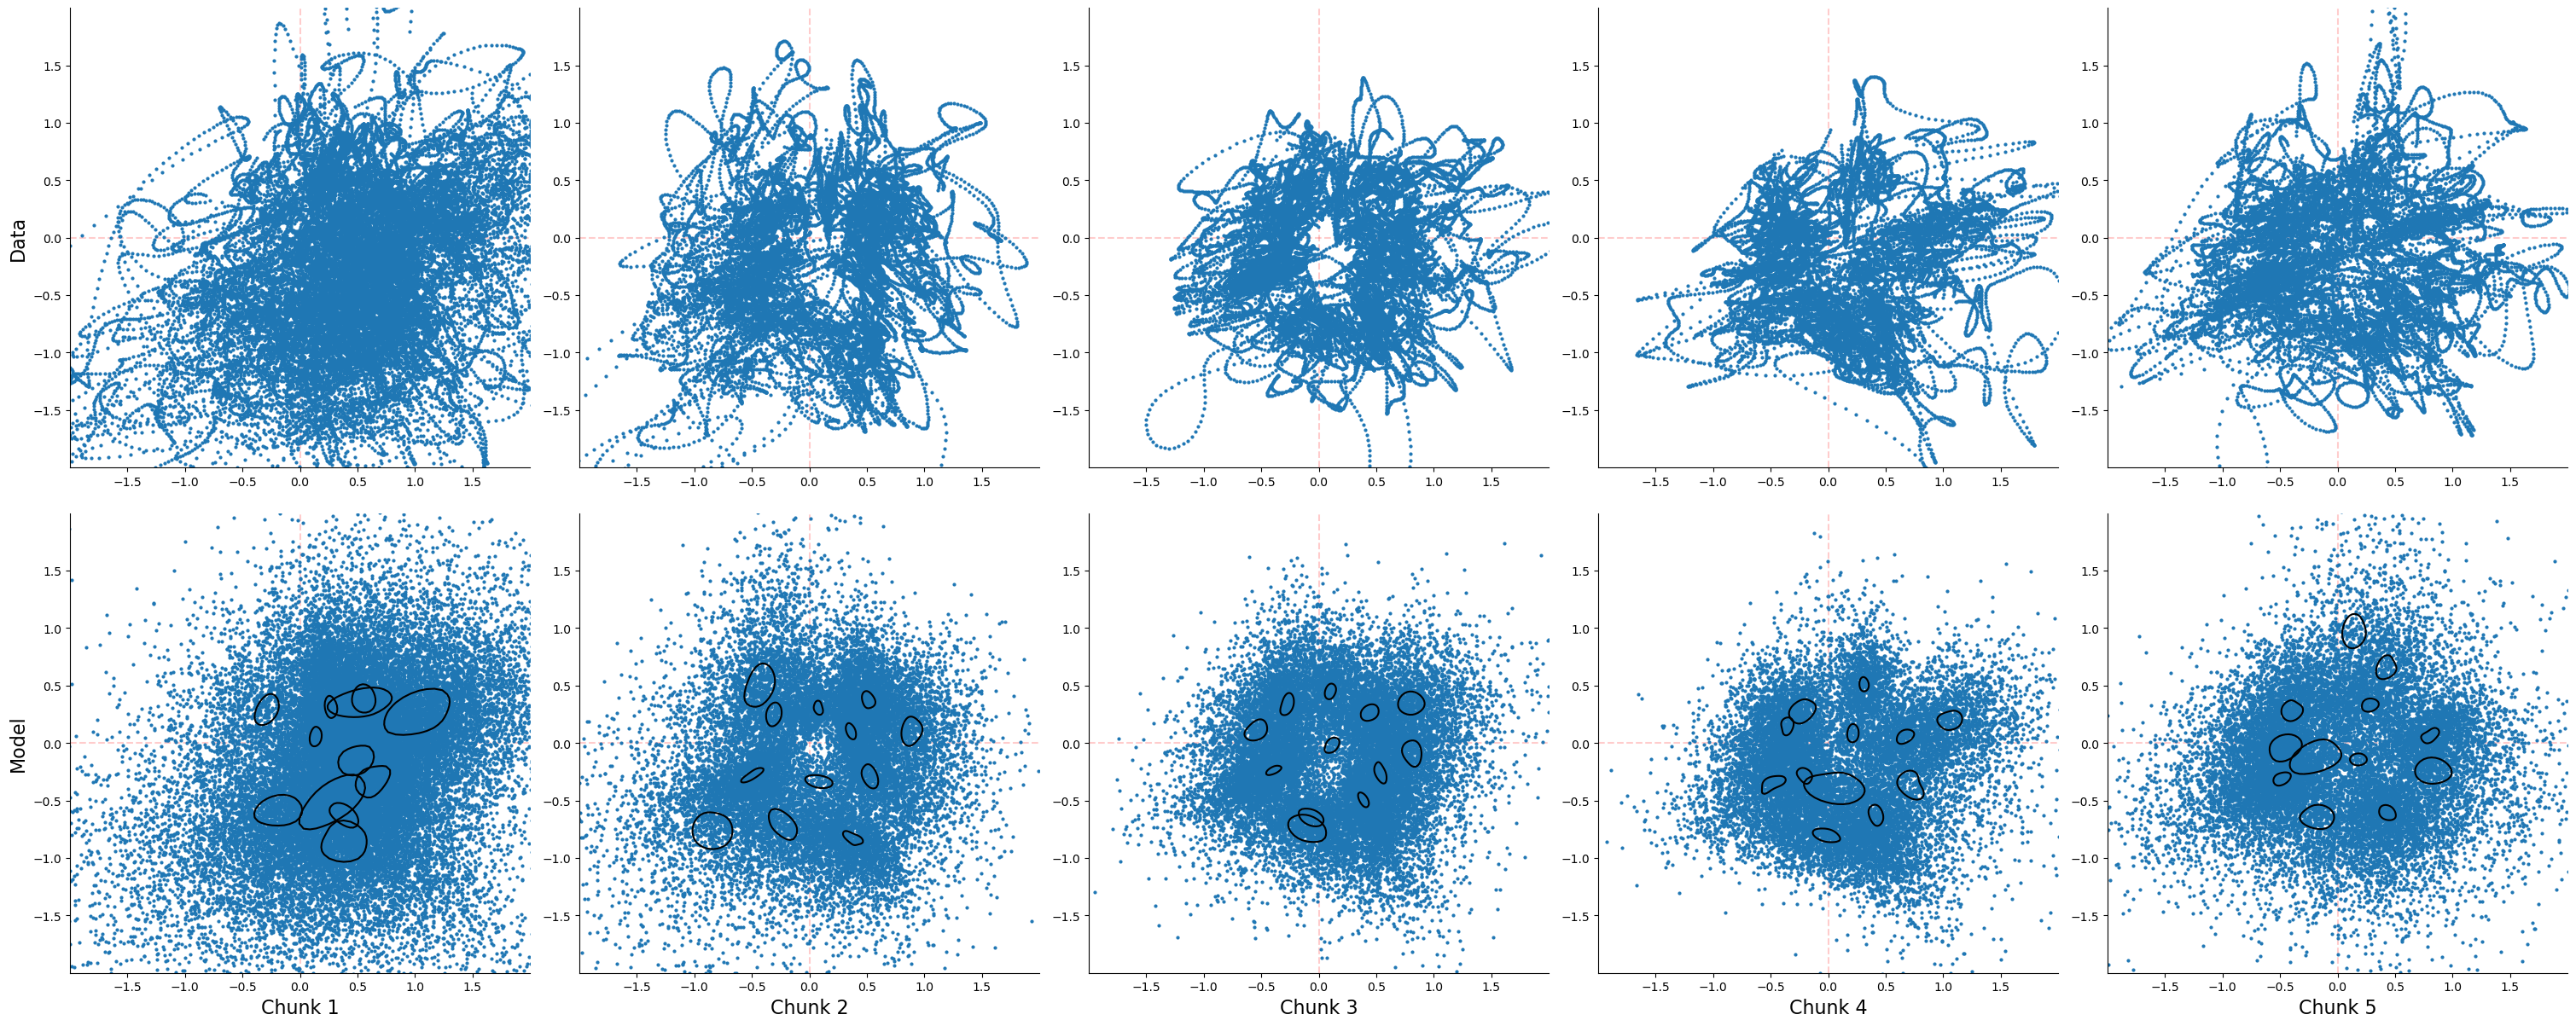

In [39]:
fig, model_axes = plt.subplots(2,5,figsize=(12*2.5,12))
fig.tight_layout()

for model_ax in model_axes.ravel():
    model_ax.set_aspect("equal")
    model_ax.set_ylim([-2,2])
    model_ax.set_xlim([-2,2])
    model_ax.plot([-2,2],[0,0],"r--",alpha=0.2)
    model_ax.plot([0,0],[-2,2],"r--",alpha=0.2)

N = 15000
for j in range(5):
    # m = models[i]
    # for (mm, cc, ww) in zip(m.means_, m.covariances_, m.weights_):
    #     mean = model.transform_mean(decoder, model.make_lognormal_mean(mm.reshape(-1,1),cc))
    #     model_axes[i,1].plot(mean[0],mean[1],"ro",markersize=500**ww)

    chunk_samples = data_samples[j]
    model_samples = model_decoded_samples[j]
    
    model_axes[0,j].plot(chunk_samples[0],chunk_samples[1],'.',markersize=4,color="tab:blue")
    # kde_plot(chunk_samples.T-offsets[subject_idx],model_axes[0,j])

    model_axes[1,j].plot(model_samples[0],model_samples[1],".",markersize=4,color="tab:blue")
    data = pd.DataFrame(model_samples.T,columns=['x','y'])


    # component plots
    subject_model = subject_models[j]
    for i in range(12):
        g = GaussianMixture(n_components=1)
        g.means_ = subject_model.means_[i].reshape(1,64)
        g.covariances_ = subject_model.covariances_[i].reshape(1,64,64)
        g.weights_ = subject_model.weights_[i].reshape(1)
        lognormal_samples = np.exp(g.sample(N)[0])
        decoded_samples = decoder @ lognormal_samples.T
        data = pd.DataFrame(decoded_samples.T,columns=['x','y'])
        sns.kdeplot(data, x='x', y='y', levels=[0.95,1.0], ax=model_axes[1,j], color='k')
        # kde_plot(model_samples.T-offsets[subject_idx],model_axes[1,j])

for i in range(2):
    for j in range(5):
        ax = model_axes[i,j]
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_xticks(np.linspace(-1.5,1.5,7,endpoint=True))
        ax.set_yticks(np.linspace(-1.5,1.5,7,endpoint=True))
        if i == 1:
            ax.set_xlabel(f"Chunk {j+1}",fontsize=16)

model_axes[0,0].set_ylabel("Data",fontsize=16)
model_axes[1,0].set_ylabel("Model",fontsize=16)

In [38]:
plot.save_figure(fig, f"subject_{subject_idx}_data_model_trial", image_path, format="png")

Figure saved to /Users/spencer/phd/phd/images/more_results/gmms/subject_16_data_model_trial.png
